# SALA — Step 04: Sentiment Analysis

**Goal:** Produce a daily sentiment score for the market using text data
(tweets / news), then save it for the SALA learning automaton.

**Why this matters:**
Financial markets react to two forces: **quantitative** (price, volume) and
**qualitative** (news, tweets, sentiment). The anomaly detector already captures
the quantitative side. This notebook captures the qualitative side.

**Pipeline:**
1. Score each text with **VADER** (a rule-based, lexicon-driven sentiment model
   tuned for social media).
2. Calibrate VADER against a labeled financial dataset (Twitter Financial News
   Sentiment) to measure how reliable it is on financial text.
3. Aggregate text scores into a **daily sentiment score**.
4. Save the daily series to `data/processed/sentiment_daily.csv`.

**Inputs:**
- `zeroshot/twitter-financial-news-sentiment` (HuggingFace dataset, ~9.5k texts)
- (for the demo daily series) synthetic texts

**Outputs:**
- `data/processed/sentiment_daily.csv`
- `results/tables/vader_calibration.csv`
- `results/tables/sentiment_summary.csv`
- `results/figures/04_sentiment_demo.png`

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "src" / "config.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not find project root")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.config import PROCESSED_DIR, FIGURES_DIR, TABLES_DIR
from src.models.sentiment import (
    score_text,
    label_from_score,
    aggregate_daily,
    save_daily_sentiment,
    save_summary,
    calibrate_on_phrasebank,
)

print(f"Project root : {PROJECT_ROOT}")
print(f"Processed dir: {PROCESSED_DIR}")
print(f"Figures dir  : {FIGURES_DIR}")
print(f"Tables dir   : {TABLES_DIR}")

Project root : /Users/saleh/Documents/project/Sentiment-Aware Learning Automaton (SALA)
Processed dir: /Users/saleh/Documents/project/Sentiment-Aware Learning Automaton (SALA)/data/processed
Figures dir  : /Users/saleh/Documents/project/Sentiment-Aware Learning Automaton (SALA)/results/figures
Tables dir   : /Users/saleh/Documents/project/Sentiment-Aware Learning Automaton (SALA)/results/tables


## 3. Quick sanity check of VADER

Before building the full pipeline, we verify that VADER behaves as expected
on obvious examples.

**Expected behavior:**
- Clearly positive texts → positive score (close to +1)
- Clearly negative texts → negative score (close to -1)
- Neutral factual statements → score near 0

In [2]:
samples = [
    "Bitcoin is going to the moon! 🚀",
    "Massive crash incoming, sell everything!",
    "BTC price unchanged today.",
    "SEC approves Bitcoin ETF, huge news!",
    "FTX collapse wipes out billions.",
]

print(f"{'Score':>8}  {'Label':<10}  Text")
print("-" * 70)
for text in samples:
    s = score_text(text)
    label = label_from_score(s)
    print(f"{s:>+8.3f}  {label:<10}  {text}")

   Score  Label       Text
----------------------------------------------------------------------
  +0.000  neutral     Bitcoin is going to the moon! 🚀
  -0.457  negative    Massive crash incoming, sell everything!
  +0.000  neutral     BTC price unchanged today.
  +0.648  positive    SEC approves Bitcoin ETF, huge news!
  -0.494  negative    FTX collapse wipes out billions.


## 4. Calibrate VADER on financial text

VADER was designed for general social media, not financial text. We measure
its accuracy on a labeled dataset of financial tweets.

**Dataset:** `zeroshot/twitter-financial-news-sentiment`
- ~9,543 training texts
- 3 classes: **Bearish (0)**, **Bullish (1)**, **Neutral (2)**
- Labels come from human annotators

**What we report:**
- Overall **accuracy** (fraction of texts where VADER's label matches gold)
- **Confusion matrix** (which classes VADER confuses most)

**Why this matters for the thesis:**
If accuracy is low (typically 40–60% for VADER on financial text), it justifies
mentioning that **FinBERT** or other finance-specific models would be a better
choice for future work, but VADER is sufficient as a **baseline** for the
prototype.

In [3]:
calib_df = calibrate_on_phrasebank()
print()
print("First 5 rows:")
calib_df[["text", "gold_label", "vader_score", "pred_label"]].head()

Calibration on 9543 texts
Accuracy: 0.481

Confusion (gold vs predicted):
pred_label  negative  neutral  positive
gold_label                             
negative         696      441       305
neutral         1137     3049      1992
positive         187      887       849

First 5 rows:


,text,gold_label,vader_score,pred_label
0,$BYND - JPMorgan reels in expectations on Beyo...,negative,0.0000,neutral
1,$CCL $RCL - Nomura points to bookings weakness...,negative,-0.4215,negative
2,"$CX - Cemex cut at Credit Suisse, J.P. Morgan ...",negative,-0.3400,negative
3,$ESS: BTIG Research cuts to Neutral https://t....,negative,-0.2960,negative
4,$FNKO - Funko slides after Piper Jaffray PT cu...,negative,-0.2732,negative


## 5. Save calibration results

Store per-text predictions so that the thesis appendix can show exactly
how VADER was evaluated.

In [4]:
TABLES_DIR.mkdir(parents=True, exist_ok=True)
calib_path = TABLES_DIR / "vader_calibration.csv"
calib_df[["text", "gold_label", "vader_score", "pred_label"]].to_csv(
    calib_path, index=False
)
print(f"Saved: {calib_path.name}  ({len(calib_df)} rows)")

Saved: vader_calibration.csv  (9543 rows)


## 6. Demo daily sentiment (synthetic)

The HuggingFace dataset does not carry timestamps aligned with our price
data (2022–2025). For the prototype pipeline, we generate a **synthetic
daily sentiment series** so that the SALA automaton can be validated
end-to-end.

In a production system, this block would be replaced by a loader that pulls
real tweets/news (e.g., from CryptoPanic, NewsAPI, or an internal database)
for each date.

**What the demo generates:**
- 30 consecutive days
- 1–3 short texts per day, drawn from positive / negative / neutral templates
- Mixture probabilities: 40% positive, 40% negative, 20% neutral

In [5]:
np.random.seed(42)

dates = pd.date_range("2022-01-01", periods=30, freq="D")

positive_texts = [
    "BTC breaking out, bullish momentum",
    "Institutions are buying, great sign",
    "ETF approval could send prices higher",
]
negative_texts = [
    "Regulatory crackdown fears, market drops",
    "Major exchange hacked, panic selling",
    "Macro outlook grim, risk-off mode",
]
neutral_texts = [
    "Bitcoin trades sideways",
    "Market waiting for Fed decision",
    "Volatility remains low",
]

rows = []
for d in dates:
    n = np.random.randint(1, 4)
    for _ in range(n):
        cat = np.random.choice(["pos", "neg", "neu"], p=[0.4, 0.4, 0.2])
        text = np.random.choice(
            positive_texts if cat == "pos"
            else negative_texts if cat == "neg"
            else neutral_texts
        )
        rows.append({"Date": d, "Text": text})

demo_df = pd.DataFrame(rows)
print(f"Synthetic dataset: {len(demo_df)} texts across {demo_df['Date'].nunique()} days")
demo_df.head(10)

Synthetic dataset: 63 texts across 30 days


,Date,Text
0,2022-01-01,"Macro outlook grim, risk-off mode"
1,2022-01-01,"Regulatory crackdown fears, market drops"
2,2022-01-01,"Major exchange hacked, panic selling"
3,2022-01-02,ETF approval could send prices higher
4,2022-01-02,Volatility remains low
5,2022-01-02,"Institutions are buying, great sign"
6,2022-01-03,"BTC breaking out, bullish momentum"
7,2022-01-03,"Major exchange hacked, panic selling"
8,2022-01-04,"BTC breaking out, bullish momentum"
9,2022-01-04,ETF approval could send prices higher


## 7. Aggregate to daily sentiment

For each day, compute:
- **Sentiment_Score**: mean of VADER compound scores across all texts of that day
- **Sentiment_Label**: positive if > 0.05, negative if < −0.05, else neutral
- **N_Texts**: number of texts that contributed to that day

The result is a single daily time series that the SALA automaton can consume.

In [6]:
daily = aggregate_daily(demo_df, date_col="Date", text_col="Text")

print(f"Daily series: {len(daily)} days")
print()
print(daily.head(10))

save_daily_sentiment(daily)
save_summary(daily)

Daily series: 30 days

        Date  Sentiment_Score  N_Texts Sentiment_Label
0 2022-01-01        -0.584767        3        negative
1 2022-01-02         0.276133        3        positive
2 2022-01-03        -0.380450        2        negative
3 2022-01-04         0.238350        2        positive
4 2022-01-05        -0.222367        3        negative
5 2022-01-06         0.476700        1        positive
6 2022-01-07         0.158900        3        positive
7 2022-01-08         0.238350        2        positive
8 2022-01-09         0.017667        3         neutral
9 2022-01-10        -0.591200        2        negative
Saved: sentiment_daily.csv  (30 rows)
Saved: sentiment_summary.csv
   Label  Days
positive    15
negative     9
 neutral     6


## 8. Visualize daily sentiment

- **Green bars** → positive days (score > 0.05)
- **Red bars** → negative days (score < −0.05)
- **Gray bars** → neutral days

This is exactly the signal that will feed into the SALA automaton alongside
the anomaly flag.

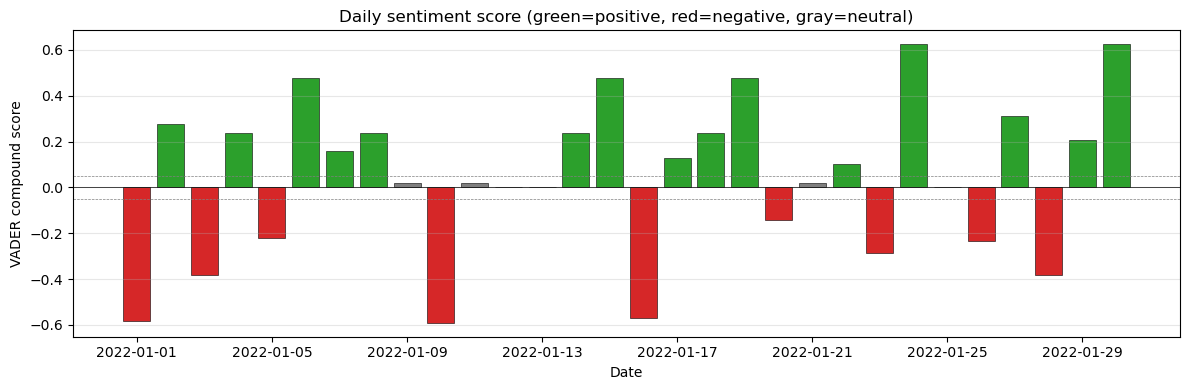

Figure saved: 04_sentiment_demo.png


In [7]:
fig, ax = plt.subplots(figsize=(12, 4))

colors = [
    "#2ca02c" if s > 0.05 else
    "#d62728" if s < -0.05 else
    "#7f7f7f"
    for s in daily["Sentiment_Score"]
]

ax.bar(daily["Date"], daily["Sentiment_Score"], color=colors,
       edgecolor="black", linewidth=0.4, width=0.8)
ax.axhline(0, color="black", linewidth=0.5)
ax.axhline( 0.05, color="gray", linestyle="--", linewidth=0.5)
ax.axhline(-0.05, color="gray", linestyle="--", linewidth=0.5)
ax.set_title("Daily sentiment score (green=positive, red=negative, gray=neutral)")
ax.set_ylabel("VADER compound score")
ax.set_xlabel("Date")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()

fig_path = FIGURES_DIR / "04_sentiment_demo.png"
fig_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Figure saved: {fig_path.name}")